In [272]:
import pandas as pd
from io import StringIO

# Read the raw CSV
with open("../data/raw/repo_data_with_factors.csv", "r", encoding="utf-8-sig") as f:
    raw = f.read()

# Remove the outer quote surrounding each line
lines = raw.splitlines()

cleaned_lines = []
for line in lines:
    if line.startswith('"') and line.endswith('"'):
        line = line[1:-1]
    cleaned_lines.append(line)

# Rebuild the CSV and load it
cleaned_csv = "\n".join(cleaned_lines)

df = pd.read_csv(
    StringIO(cleaned_csv),
    sep=",",
    quotechar='"',
    doublequote=True
)

print("Dataset shape:", df.shape)

Dataset shape: (1266, 174)


In [273]:
print("Dataset shape:", df.shape)

print("\nFirst 10 columns:")
print(df.columns[:10].tolist())

print("\nLast 10 columns:")
print(df.columns[-10:].tolist())

print("\nFirst 5 rows:")
display(df.head())

Dataset shape: (1266, 174)

First 10 columns:
['Unnamed: 0', 'ID""', 'Gender""', 'Age""', 'Year""', 'Programme""', 'Grade""', 'Diagnosis_1""', 'Diagnosis_2""', 'Diagnosis_3""']

Last 10 columns:
['Which_subjects_14""', 'Use_F""', 'P_AI""', 'AI_P""', 'AI_S""', 'S_AI""', 'AI_K""', 'T_AI_W""', 'T_AI_U""', 'gender_binary""']

First 5 rows:


,Unnamed: 0,"ID""""","Gender""""","Age""""","Year""""","Programme""""","Grade""""","Diagnosis_1""""","Diagnosis_2""""","Diagnosis_3""""",...,"Which_subjects_14""""","Use_F""""","P_AI""""","AI_P""""","AI_S""""","S_AI""""","AI_K""""","T_AI_W""""","T_AI_U""""","gender_binary"""""
0,1,"S1_E6""""",2,19,3,17,3,2.0,2.0,2.0,...,2.0,8.0,1.306762,1.458253,0.431869,-0.987621,-0.483145,0.951602,0.670221,"female"""""
1,2,"S1_E9""""",2,17,2,17,3,2.0,2.0,2.0,...,2.0,6.0,0.948598,0.528929,0.092723,-0.951044,-0.088695,0.949042,1.427199,"female"""""
2,3,"S1_E10""""",1,17,2,15,3,2.0,2.0,2.0,...,2.0,6.0,0.374103,0.162455,1.243620,0.415043,0.906967,-0.194152,-0.515959,"male"""""
3,4,"S1_E11""""",2,17,1,17,2,2.0,2.0,2.0,...,2.0,6.0,-0.288456,-1.140215,-0.718284,-0.677815,0.356440,0.761499,0.442906,"female"""""
4,5,"S1_E12""""",1,19,0,15,4,2.0,2.0,2.0,...,NaN,2.0,-0.470219,-0.417538,-0.360040,-0.293748,0.897846,-0.218139,-0.899568,"male"""""


In [274]:
# Clean column names
df.columns = df.columns.str.replace('"', '', regex=False).str.strip()

# Show the cleaned columns
print("First 10 columns:")
print(df.columns[:10].tolist())

print("\nLast 10 columns:")
print(df.columns[-10:].tolist())

First 10 columns:
['Unnamed: 0', 'ID', 'Gender', 'Age', 'Year', 'Programme', 'Grade', 'Diagnosis_1', 'Diagnosis_2', 'Diagnosis_3']

Last 10 columns:
['Which_subjects_14', 'Use_F', 'P_AI', 'AI_P', 'AI_S', 'S_AI', 'AI_K', 'T_AI_W', 'T_AI_U', 'gender_binary']


In [275]:
print(df["Unnamed: 0"].head(10).tolist())
print(df["Unnamed: 0"].tail(10).tolist())

print("\nData types:")
print(df.dtypes.head(15))

[1, 2, 3, 4, 5, 6, 7, 8, 9, 10]
[1257, 1258, 1259, 1260, 1261, 1262, 1263, 1264, 1265, 1266]

Data types:
Unnamed: 0       int64
ID                 str
Gender           int64
Age              int64
Year             int64
Programme        int64
Grade            int64
Diagnosis_1    float64
Diagnosis_2    float64
Diagnosis_3    float64
Diagnosis_4    float64
Diagnosis_5    float64
Diagnosis_6    float64
Diagnosis_8    float64
Diagnosis_9    float64
dtype: object


In [276]:
# Remove the original row-number column
df = df.drop(columns=["Unnamed: 0"])

print("Dataset shape:", df.shape)
print("\nNumber of columns:", len(df.columns))
print("\nFirst 10 columns:")
print(df.columns[:10].tolist())

Dataset shape: (1266, 173)

Number of columns: 173

First 10 columns:
['ID', 'Gender', 'Age', 'Year', 'Programme', 'Grade', 'Diagnosis_1', 'Diagnosis_2', 'Diagnosis_3', 'Diagnosis_4']


In [277]:
# Check missing values
missing = df.isnull().sum()

print("Columns with missing values:")
print(missing[missing > 0].sort_values(ascending=False))

Columns with missing values:
Years_in_swedish_school         1188
S_tips_relating_to_diagnosis    1047
S_AI_helps_difficulties         1046
Why_not_AI_7                     700
Why_not_AI_2                     700
                                ... 
S_teachers_use_AI                  8
S_perspectives                     8
S_rules                            7
Use_school                         5
AI_Access                          1
Length: 90, dtype: int64


In [278]:
# Load the survey codebook
codebook = pd.read_excel("../data/raw/Variables_repo_data.xlsx")

print("Codebook shape:", codebook.shape)
print("\nCodebook columns:")
print(codebook.columns.tolist())

display(codebook.head())

Codebook shape: (163, 6)

Codebook columns:
['Variable Name', 'Label', 'Type', 'Data Type', 'Value Codes', 'Missing Code']


,Variable Name,Label,Type,Data Type,Value Codes,Missing Code
0,Gender,Jag är:,Single-Choice - Radio Buttons,Numeric,1 = Man\n2 = Kvinna\n3 = Annat\n4 = Vill inte ...,999.0
1,Age,Ålder,Numeric - Field,Numeric,none,NaN
2,Year,Vilken årskurs går du i?,Single-Choice - Radio Buttons,Numeric,1 = 1\n2 = 2\n3 = 3\n0 = Annat/Vill ej svara,999.0
3,Programme,Vilket program går du?,Single-Choice - Drop Down List,Numeric,1 = Barn- och fritidsprogrammet\n2 = Bygg- och...,999.0
4,Grade,Mitt genomsnittliga betyg förra året var ungefär:,Single-Choice - Drop Down List,Numeric,1 = A\n2 = B\n3 = C\n4 = D\n5 = E\n6 = F\n0 = ...,999.0


In [279]:
# Compare variable names between the dataset and codebook
dataset_variables = set(df.columns)
codebook_variables = set(codebook["Variable Name"].dropna().astype(str).str.strip())

documented = sorted(dataset_variables & codebook_variables)
undocumented = sorted(dataset_variables - codebook_variables)

print("Variables in dataset:", len(dataset_variables))
print("Variables matched to codebook:", len(documented))
print("Variables not matched to codebook:", len(undocumented))

print("\nVariables not matched:")
print(undocumented)

Variables in dataset: 173
Variables matched to codebook: 163
Variables not matched to codebook: 10

Variables not matched:
['AI_K', 'AI_P', 'AI_S', 'ID', 'P_AI', 'S_AI', 'T_AI_U', 'T_AI_W', 'Use_F', 'gender_binary']


In [280]:
# Display the codebook entries related to AI use
ai_variables = codebook[
    codebook["Variable Name"].astype(str).str.contains(
        "Use_AI|Use_F|P_AI|AI_P|AI_S|S_AI|AI_K|T_AI",
        case=False,
        regex=True,
        na=False
    )
]

display(ai_variables[
    ["Variable Name", "Label", "Value Codes", "Missing Code"]
])

,Variable Name,Label,Value Codes,Missing Code
71,Why_not_AI_1,Om du inte eller sällan använder AI för skolar...,1 = Ja\n2 = Nej,999.0
72,Why_not_AI_2,Om du inte eller sällan använder AI för skolar...,1 = Ja\n2 = Nej,999.0
73,Why_not_AI_3,Om du inte eller sällan använder AI för skolar...,1 = Ja\n2 = Nej,999.0
74,Why_not_AI_4,Om du inte eller sällan använder AI för skolar...,1 = Ja\n2 = Nej,999.0
75,Why_not_AI_5,Om du inte eller sällan använder AI för skolar...,1 = Ja\n2 = Nej,999.0
76,Why_not_AI_6,Om du inte eller sällan använder AI för skolar...,1 = Ja\n2 = Nej,999.0
77,Why_not_AI_7,Om du inte eller sällan använder AI för skolar...,1 = Ja\n2 = Nej,999.0
97,Use_AI_secretly,Här följer ett antal påståenden om AI för stud...,1 = Stämmer inte alls\n2 = Stämmer mestadels i...,999.0
107,Use_feedback,Här följer ett antal påståenden om AI för stud...,1 = Stämmer inte alls\n2 = Stämmer mestadels i...,999.0
120,K_use_AI_to_task,Här följer några påståenden om dina kunskaper ...,1 = Stämmer inte alls\n2 = Stämmer mestadels i...,999.0


In [281]:

# Explore potential target variables

# Check which potential AI-related variables exist in the dataset
candidate_variables = [
    "Use_AI_secretly",
    "Use_feedback",
    "K_use_AI_to_task",
    "S_teachers_use_AI",
    "S_teachers_help_use_AI",
    "S_education_about_AI",
    "S_AI_helps_difficulties",
    "ST_AI_is",
    "ST_AI_works",
    "ST_AI_affects_society",
    "ST_AI_for_work",
    "ST_AI_for_life",
]

available_variables = [
    col for col in candidate_variables if col in df.columns
]

print("Available candidate variables:", len(available_variables))
print()

for col in available_variables:
    print(f"\n--- {col} ---")
    print(df[col].value_counts(dropna=False).sort_index())


Available candidate variables: 12


--- Use_AI_secretly ---
Use_AI_secretly
0.0     51
1.0    429
2.0    182
3.0    156
4.0    112
5.0     70
NaN    266
Name: count, dtype: int64

--- Use_feedback ---
Use_feedback
0.0     58
1.0    306
2.0    154
3.0    154
4.0    212
5.0    116
NaN    266
Name: count, dtype: int64

--- K_use_AI_to_task ---
K_use_AI_to_task
0    127
1    416
2    214
3    230
4    162
5    117
Name: count, dtype: int64

--- S_teachers_use_AI ---
S_teachers_use_AI
0.0    304
1.0    139
2.0    186
3.0    264
4.0    240
5.0    125
NaN      8
Name: count, dtype: int64

--- S_teachers_help_use_AI ---
S_teachers_help_use_AI
0.0    105
1.0    400
2.0    166
3.0    187
4.0    224
5.0    174
NaN     10
Name: count, dtype: int64

--- S_education_about_AI ---
S_education_about_AI
0.0    107
1.0    531
2.0    184
3.0    176
4.0    177
5.0     80
NaN     11
Name: count, dtype: int64

--- S_AI_helps_difficulties ---
S_AI_helps_difficulties
0.0      42
1.0      68
2.0      16
3.0    

ST_AI_for_life
1.0    112
2.0    255
3.0    384
4.0    222
5.0    146
NaN    147
Name: count, dtype: int64


In [282]:

# Summarize AI-related variables

summary = []

for col in available_variables:
    valid = df[col].dropna()

    summary.append({
        "Variable": col,
        "Valid Responses": len(valid),
        "Missing Responses": df[col].isna().sum(),
        "Unique Values": sorted(valid.unique().tolist()),
        "Most Common Answer": (
            valid.mode().iloc[0] if not valid.mode().empty else None
        )
    })

summary_df = pd.DataFrame(summary)

display(summary_df)


,Variable,Valid Responses,Missing Responses,Unique Values,Most Common Answer
0,Use_AI_secretly,1000,266,"[0.0, 1.0, 2.0, 3.0, 4.0, 5.0]",1.0
1,Use_feedback,1000,266,"[0.0, 1.0, 2.0, 3.0, 4.0, 5.0]",1.0
2,K_use_AI_to_task,1266,0,"[0, 1, 2, 3, 4, 5]",1.0
3,S_teachers_use_AI,1258,8,"[0.0, 1.0, 2.0, 3.0, 4.0, 5.0]",0.0
4,S_teachers_help_use_AI,1256,10,"[0.0, 1.0, 2.0, 3.0, 4.0, 5.0]",1.0
5,S_education_about_AI,1255,11,"[0.0, 1.0, 2.0, 3.0, 4.0, 5.0]",1.0
6,S_AI_helps_difficulties,220,1046,"[0.0, 1.0, 2.0, 3.0, 4.0, 5.0]",1.0
7,ST_AI_is,1141,125,"[1.0, 2.0, 3.0, 4.0, 5.0]",4.0
8,ST_AI_works,1142,124,"[1.0, 2.0, 3.0, 4.0, 5.0]",4.0
9,ST_AI_affects_society,1147,119,"[1.0, 2.0, 3.0, 4.0, 5.0]",4.0


In [283]:

# Examine potential target variables

target_candidates = [
    "Use_AI_secretly",
    "Use_feedback",
    "K_use_AI_to_task"
]

# Find the codebook column containing variable names
name_column = next(
    col for col in codebook.columns
    if "variable name" in str(col).lower()
)

selected = codebook[
    codebook[name_column].astype(str).str.strip().isin(target_candidates)
]

for _, row in selected.iterrows():
    print("\n" + "=" * 60)
    for col in codebook.columns:
        print(f"{col}: {row[col]}")



Variable Name: Use_AI_secretly
Label: Här följer ett antal påståenden om AI för studier, där vi ber dig svara med generativ AI i åtanke.  - Jag använder AI-genererad text eller bilder i mitt skolarbete utan att tala om det för läraren
Type: Matrix - Radio Buttons
Data Type: Numeric
Value Codes: 1 = Stämmer inte alls
2 = Stämmer mestadels inte
3 = Varken stämmer eller inte
4 = Stämmer till stor del
5 = Stämmer helt
0 = Vet ej
Missing Code: 999.0

Variable Name: Use_feedback
Label: Här följer ett antal påståenden om AI för studier, där vi ber dig svara med generativ AI i åtanke.  - Jag använder AI för att få återkoppling på mitt arbete
Type: Matrix - Radio Buttons
Data Type: Numeric
Value Codes: 1 = Stämmer inte alls
2 = Stämmer mestadels inte
3 = Varken stämmer eller inte
4 = Stämmer till stor del
5 = Stämmer helt
0 = Vet ej
Missing Code: 999.0

Variable Name: K_use_AI_to_task
Label: Här följer några påståenden om dina kunskaper om AI. - Jag använder olika AI-tjänster beroende på vad j

In [284]:

# Create a binary classification target

# Keep the original dataset unchanged
model_df = df.copy()

# Define valid response groups
target_mapping = {
    1: 0,
    2: 0,
    4: 1,
    5: 1
}

# Create the new target variable
model_df["AI_Secret_Use_Target"] = (
    model_df["Use_AI_secretly"].map(target_mapping)
)

# Remove rows without a defined target
model_df = model_df.dropna(
    subset=["AI_Secret_Use_Target"]
).copy()

# Convert target to integer
model_df["AI_Secret_Use_Target"] = (
    model_df["AI_Secret_Use_Target"].astype(int)
)

# Display results
print("Original dataset:", df.shape)
print("Modeling dataset:", model_df.shape)

print("\nTarget distribution:")
print(
    model_df["AI_Secret_Use_Target"]
    .value_counts()
    .sort_index()
)

print("\nTarget percentages:")
print(
    model_df["AI_Secret_Use_Target"]
    .value_counts(normalize=True)
    .sort_index()
    .mul(100)
    .round(2)
)


Original dataset: (1266, 173)
Modeling dataset: (793, 174)

Target distribution:
AI_Secret_Use_Target
0    611
1    182
Name: count, dtype: int64

Target percentages:
AI_Secret_Use_Target
0    77.05
1    22.95
Name: proportion, dtype: float64


In [285]:

# Split data into training and testing sets

from sklearn.model_selection import train_test_split

# Split row indices while preserving target proportions
train_idx, test_idx = train_test_split(
    model_df.index,
    test_size=0.20,
    random_state=42,
    stratify=model_df["AI_Secret_Use_Target"]
)

train_df = model_df.loc[train_idx].copy()
test_df = model_df.loc[test_idx].copy()

print("Training students:", len(train_df))
print("Testing students:", len(test_df))

print("\nTraining target percentages:")
print(
    train_df["AI_Secret_Use_Target"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

print("\nTesting target percentages:")
print(
    test_df["AI_Secret_Use_Target"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)


Training students: 634
Testing students: 159

Training target percentages:
AI_Secret_Use_Target
0    76.97
1    23.03
Name: proportion, dtype: float64

Testing target percentages:
AI_Secret_Use_Target
0    77.36
1    22.64
Name: proportion, dtype: float64


In [286]:

# Examine potential predictor variables

candidate_predictors = [
    "Gender",
    "Age",
    "Year",
    "Programme",
    "Grade",
    "AI_Access",
    "Use_school",
    "Use_feedback",
    "K_use_AI_to_task",
    "S_teachers_use_AI",
    "S_teachers_help_use_AI",
    "S_education_about_AI"
]

# Check which variables exist
available_predictors = [
    col for col in candidate_predictors
    if col in train_df.columns
]

# Display variable information
predictor_summary = pd.DataFrame({
    "Variable": available_predictors,
    "Data Type": [
        train_df[col].dtype
        for col in available_predictors
    ],
    "Missing Values": [
        train_df[col].isna().sum()
        for col in available_predictors
    ],
    "Unique Values": [
        train_df[col].nunique(dropna=True)
        for col in available_predictors
    ]
})

display(predictor_summary)


,Variable,Data Type,Missing Values,Unique Values
0,Gender,int64,0,4
1,Age,int64,0,6
2,Year,int64,0,4
3,Programme,int64,0,17
4,Grade,int64,0,6
5,AI_Access,float64,1,6
6,Use_school,float64,2,5
7,Use_feedback,float64,0,6
8,K_use_AI_to_task,int64,0,6
9,S_teachers_use_AI,float64,4,6


In [287]:

# Review predictor definitions and response codes

for variable in available_predictors:

    matching_rows = codebook[
        codebook["Variable Name"].astype(str).str.strip() == variable
    ]

    print("\n" + "=" * 60)
    print("VARIABLE:", variable)

    if matching_rows.empty:
        print("Not found in codebook.")
        continue

    row = matching_rows.iloc[0]

    print("Description:", row["Label"])
    print("Response codes:", row["Value Codes"])
    print("Missing code:", row["Missing Code"])



VARIABLE: Gender
Description: Jag är: 
Response codes: 1 = Man
2 = Kvinna
3 = Annat
4 = Vill inte uppge
Missing code: 999.0

VARIABLE: Age
Description: Ålder
Response codes: none
Missing code: nan

VARIABLE: Year
Description: Vilken årskurs går du i?
Response codes: 1 = 1
2 = 2
3 = 3
0 = Annat/Vill ej svara
Missing code: 999.0

VARIABLE: Programme
Description: Vilket program går du?
Response codes: 1 = Barn- och fritidsprogrammet
2 = Bygg- och anläggningsprogrammet
3 = Ekonomiprogrammet
4 = El- och energiprogrammet
5 = Estetiska programmet
6 = Fordons- och transportprogrammet
7 = Försäljnings- och serviceprogrammet
8 = Handels- och administrationsprogrammet
9 = Hantverksprogrammet
10 = Hotell- och turismprogrammet
11 = Humanistiska programmet
12 = Industritekniska programmet
13 = Introduktionsprogram
14 = Naturbruksprogrammet
15 = Naturvetenskapsprogrammet
16 = Restaurang- och livsmedelsprogrammet
17 = Samhällsvetenskapsprogrammet
18 = Teknikprogrammet
19 = VVS- och fastighetsprogramm

In [288]:

# Create a compact predictor codebook

for variable in available_predictors:

    matching = codebook[
        codebook["Variable Name"].astype(str).str.strip() == variable
    ]

    if matching.empty:
        print(f"{variable}: Not found")
        continue

    row = matching.iloc[0]

    print(f"\nVARIABLE: {variable}")
    print("Response codes:", row["Value Codes"])
    print("Missing code:", row["Missing Code"])
    print("Actual values:", sorted(
        train_df[variable].dropna().unique().tolist()
    ))



VARIABLE: Gender
Response codes: 1 = Man
2 = Kvinna
3 = Annat
4 = Vill inte uppge
Missing code: 999.0
Actual values: [1, 2, 3, 4]

VARIABLE: Age
Response codes: none
Missing code: nan
Actual values: [15, 16, 17, 18, 19, 20]

VARIABLE: Year
Response codes: 1 = 1
2 = 2
3 = 3
0 = Annat/Vill ej svara
Missing code: 999.0
Actual values: [0, 1, 2, 3]

VARIABLE: Programme
Response codes: 1 = Barn- och fritidsprogrammet
2 = Bygg- och anläggningsprogrammet
3 = Ekonomiprogrammet
4 = El- och energiprogrammet
5 = Estetiska programmet
6 = Fordons- och transportprogrammet
7 = Försäljnings- och serviceprogrammet
8 = Handels- och administrationsprogrammet
9 = Hantverksprogrammet
10 = Hotell- och turismprogrammet
11 = Humanistiska programmet
12 = Industritekniska programmet
13 = Introduktionsprogram
14 = Naturbruksprogrammet
15 = Naturvetenskapsprogrammet
16 = Restaurang- och livsmedelsprogrammet
17 = Samhällsvetenskapsprogrammet
18 = Teknikprogrammet
19 = VVS- och fastighetsprogrammet
20 = Vård- och o

In [289]:

# Review remaining predictor response codes

variables_to_check = [
    "Grade",
    "AI_Access",
    "Use_school",
    "K_use_AI_to_task",
    "S_teachers_use_AI"
]

for variable in variables_to_check:
    matching = codebook[
        codebook["Variable Name"].astype(str).str.strip() == variable
    ]

    if matching.empty:
        print(f"{variable}: Not found")
        continue

    row = matching.iloc[0]

    print("\n" + "=" * 45)
    print("VARIABLE:", variable)
    print("Response codes:", row["Value Codes"])
    print("Actual values:", sorted(
        train_df[variable].dropna().unique().tolist()
    ))



VARIABLE: Grade
Response codes: 1 = A
2 = B
3 = C
4 = D
5 = E
6 = F
0 = Vet ej/Vill ej svara
Actual values: [0, 1, 2, 3, 4, 5]

VARIABLE: AI_Access
Response codes: 1 = Jag har tillgång till betalt konto på någon AI-tjänst
2 = Jag har ett gratiskonto på någon AI-tjänst
3 = Jag har tillgång till AI via skolan
4 = Jag använder AI-tjänster som inte kräver konto
5 = Jag har ingen tillgång till AI-tjänster
0 = Vet ej
Actual values: [0.0, 1.0, 2.0, 3.0, 4.0, 5.0]

VARIABLE: Use_school
Response codes: 1 = Varje dag
2 = Några gånger i veckan
3 = Några gånger i månaden
4 = Mer sällan
5 = Aldrig
6 = Vet ej
Actual values: [0.0, 2.0, 3.0, 4.0, 5.0]

VARIABLE: K_use_AI_to_task
Response codes: 1 = Stämmer inte alls
2 = Stämmer mestadels inte
3 = Varken stämmer eller inte
4 = Stämmer till stor del
5 = Stämmer helt
0 = Vet ej
Actual values: [0, 1, 2, 3, 4, 5]

VARIABLE: S_teachers_use_AI
Response codes: 1 = Stämmer inte alls
2 = Stämmer mestadels inte
3 = Varken stämmer eller inte
4 = Stämmer till sto

In [290]:

# Check remaining response codes

variables = [
    "Use_school",
    "K_use_AI_to_task",
    "S_teachers_use_AI",
    "S_teachers_help_use_AI",
    "S_education_about_AI"
]

for variable in variables:
    matching = codebook[
        codebook["Variable Name"].astype(str).str.strip() == variable
    ]

    if matching.empty:
        continue

    codes = str(matching.iloc[0]["Value Codes"])

    print(f"\n{variable}:")
    print(codes.replace("\n", " | "))



Use_school:
1 = Varje dag | 2 = Några gånger i veckan | 3 = Några gånger i månaden | 4 = Mer sällan | 5 = Aldrig | 6 = Vet ej

K_use_AI_to_task:
1 = Stämmer inte alls | 2 = Stämmer mestadels inte | 3 = Varken stämmer eller inte | 4 = Stämmer till stor del | 5 = Stämmer helt | 0 = Vet ej

S_teachers_use_AI:
1 = Stämmer inte alls | 2 = Stämmer mestadels inte | 3 = Varken stämmer eller inte | 4 = Stämmer till stor del | 5 = Stämmer helt | 0 = Vet ej

S_teachers_help_use_AI:
1 = Stämmer inte alls | 2 = Stämmer mestadels inte | 3 = Varken stämmer eller inte | 4 = Stämmer till stor del | 5 = Stämmer helt | 0 = Vet ej

S_education_about_AI:
1 = Stämmer inte alls | 2 = Stämmer mestadels inte | 3 = Varken stämmer eller inte | 4 = Stämmer till stor del | 5 = Stämmer helt | 0 = Vet ej


In [291]:

# Define predictor groups

import numpy as np

# Numerical variables
numeric_features = [
    "Age"
]

# Categorical variables
categorical_features = [
    "Gender",
    "Year",
    "Programme",
    "Grade",
    "AI_Access"
]

# Ordered survey response variables
ordinal_features = [
    "Use_school",
    "Use_feedback",
    "K_use_AI_to_task",
    "S_teachers_use_AI",
    "S_teachers_help_use_AI",
    "S_education_about_AI"
]

# Combine predictors
feature_columns = (
    numeric_features
    + categorical_features
    + ordinal_features
)

# Separate features and target
X_train = train_df[feature_columns].copy()
X_test = test_df[feature_columns].copy()

y_train = train_df["AI_Secret_Use_Target"]
y_test = test_df["AI_Secret_Use_Target"]

# Handle special survey response codes
# 0 = Don't know for agreement questions
agreement_features = [
    col for col in ordinal_features
    if col != "Use_school"
]

X_train[agreement_features] = (
    X_train[agreement_features].replace(0, np.nan)
)

X_test[agreement_features] = (
    X_test[agreement_features].replace(0, np.nan)
)

# Use_school: 6 = Don't know
X_train["Use_school"] = (
    X_train["Use_school"].replace(6, np.nan)
)

X_test["Use_school"] = (
    X_test["Use_school"].replace(6, np.nan)
)

# Check results
print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nSelected predictors:")
print(X_train.columns.tolist())

print("\nMissing values after handling unknown responses:")
print(X_train.isna().sum())


Training features: (634, 12)
Testing features: (159, 12)

Selected predictors:
['Age', 'Gender', 'Year', 'Programme', 'Grade', 'AI_Access', 'Use_school', 'Use_feedback', 'K_use_AI_to_task', 'S_teachers_use_AI', 'S_teachers_help_use_AI', 'S_education_about_AI']

Missing values after handling unknown responses:
Age                         0
Gender                      0
Year                        0
Programme                   0
Grade                       0
AI_Access                   1
Use_school                  2
Use_feedback               14
K_use_AI_to_task           37
S_teachers_use_AI         142
S_teachers_help_use_AI     33
S_education_about_AI       36
dtype: int64


In [292]:

# Build preprocessing pipeline

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Numerical preprocessing
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Ordinal preprocessing
ordinal_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Combine preprocessing steps
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features),
        ("ord", ordinal_transformer, ordinal_features)
    ]
)

print("Preprocessing pipeline created successfully!")


Preprocessing pipeline created successfully!


In [293]:

# Train three machine learning models

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline

# Define models
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=42
    ),

    "Decision Tree": DecisionTreeClassifier(
        max_depth=5,
        class_weight="balanced",
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        class_weight="balanced",
        random_state=42
    )
}

# Store trained models
trained_models = {}

# Train each model using the same preprocessing pipeline
for name, model in models.items():

    pipeline = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("classifier", model)
    ])

    pipeline.fit(X_train, y_train)

    trained_models[name] = pipeline

    print(f"{name} trained successfully!")

print("\nAll three models finished training!")


Logistic Regression trained successfully!
Decision Tree trained successfully!
Random Forest trained successfully!

All three models finished training!


In [294]:

# Evaluate all three models

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

import pandas as pd

results = []

for name, pipeline in trained_models.items():

    # Make predictions using testing data
    y_pred = pipeline.predict(X_test)

    # Calculate performance metrics
    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred, zero_division=0)
    recall = recall_score(y_test, y_pred, zero_division=0)
    f1 = f1_score(y_test, y_pred, zero_division=0)

    results.append({
        "Model": name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1-Score": f1
    })

    print(f"\n{'=' * 50}")
    print(name)
    print("=" * 50)

    print(classification_report(
        y_test,
        y_pred,
        zero_division=0
    ))

    print("Confusion Matrix:")
    print(confusion_matrix(y_test, y_pred))

# Create comparison table
results_df = pd.DataFrame(results)

print("\nMODEL COMPARISON:")
display(results_df.round(3))



Logistic Regression
              precision    recall  f1-score   support

           0       0.83      0.73      0.78       123
           1       0.35      0.50      0.41        36

    accuracy                           0.68       159
   macro avg       0.59      0.62      0.60       159
weighted avg       0.72      0.68      0.70       159

Confusion Matrix:
[[90 33]
 [18 18]]

Decision Tree
              precision    recall  f1-score   support

           0       0.81      0.82      0.82       123
           1       0.37      0.36      0.37        36

    accuracy                           0.72       159
   macro avg       0.59      0.59      0.59       159
weighted avg       0.71      0.72      0.72       159

Confusion Matrix:
[[101  22]
 [ 23  13]]

Random Forest
              precision    recall  f1-score   support

           0       0.80      0.87      0.84       123
           1       0.38      0.28      0.32        36

    accuracy                           0.74       159

,Model,Accuracy,Precision,Recall,F1-Score
0,Logistic Regression,0.679,0.353,0.500,0.414
1,Decision Tree,0.717,0.371,0.361,0.366
2,Random Forest,0.736,0.385,0.278,0.323


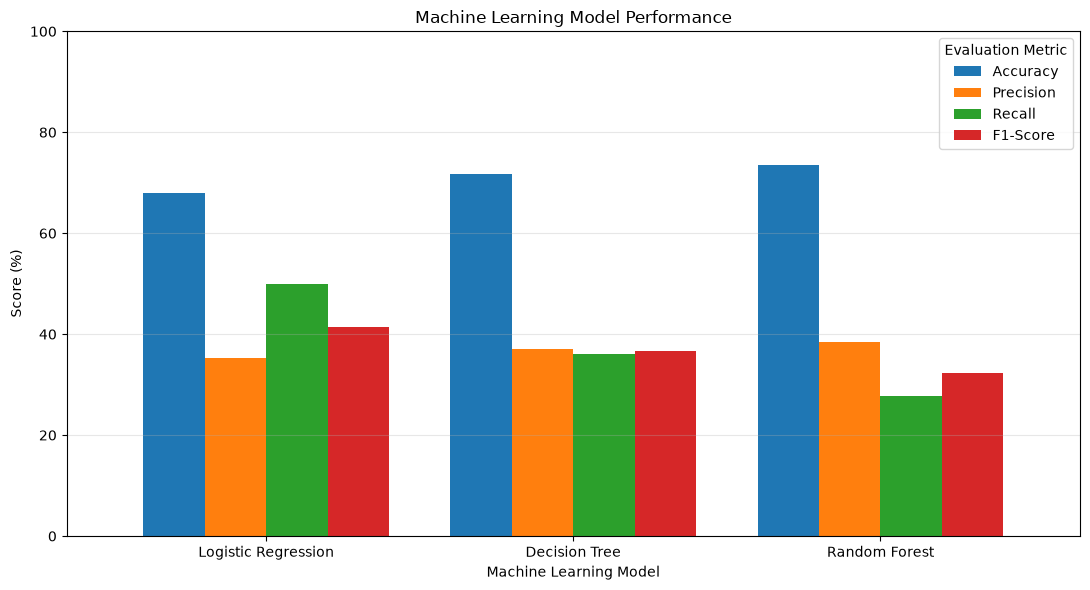

Graph saved successfully!


In [295]:

# Visualize and save model comparison

import matplotlib.pyplot as plt
from pathlib import Path

# Create results folder if needed
output_dir = Path("../results/figures")
output_dir.mkdir(parents=True, exist_ok=True)

# Prepare chart data
chart_df = results_df.set_index("Model") * 100

# Create bar chart
ax = chart_df.plot(
    kind="bar",
    figsize=(11, 6),
    width=0.8
)

plt.title("Machine Learning Model Performance")
plt.ylabel("Score (%)")
plt.xlabel("Machine Learning Model")
plt.ylim(0, 100)
plt.xticks(rotation=0)
plt.legend(title="Evaluation Metric")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

# Save figure
plt.savefig(
    output_dir / "model_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Graph saved successfully!")
